In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
# Download the SMS Spam Dataset

import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam.zip")

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
# Load the SMS Spam Dataset

data = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

# Display first 10 messages
print(data.head(10))

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
5  spam  FreeMsg Hey there darling it's been 3 week's n...
6   ham  Even my brother is not like to speak with me. ...
7   ham  As per your request 'Melle Melle (Oru Minnamin...
8  spam  WINNER!! As a valued network customer you have...
9  spam  Had your mobile 11 months or more? U R entitle...


In [4]:
print("Dataset Shape:", data.shape)
print("\nLabel Counts:")
print(data["label"].value_counts())

Dataset Shape: (5572, 2)

Label Counts:
label
ham     4825
spam     747
Name: count, dtype: int64


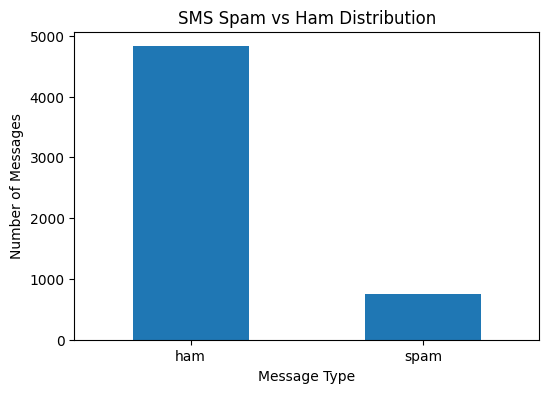

In [5]:
# Visualize the distribution of messages

data["label"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Check missing values

print(data.isnull().sum())

label      0
message    0
dtype: int64


In [7]:
# Text preprocessing

# Remove duplicate messages
data = data.drop_duplicates()

# Convert messages into lowercase
data["message"] = data["message"].str.lower()

# Remove extra spaces
data["message"] = data["message"].str.strip()

print("Text preprocessing completed!")
print("Updated Dataset Shape:", data.shape)

# Display sample messages
print("\nSample Messages:")
print(data.head())

Text preprocessing completed!
Updated Dataset Shape: (5169, 2)

Sample Messages:
  label                                            message
0   ham  go until jurong point, crazy.. available only ...
1   ham                      ok lar... joking wif u oni...
2  spam  free entry in 2 a wkly comp to win fa cup fina...
3   ham  u dun say so early hor... u c already then say...
4   ham  nah i don't think he goes to usf, he lives aro...


In [8]:
# Convert text into numerical values using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Separate messages and labels
X = data["message"]
y = data["label"]

# Convert labels into numbers
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(X_train).toarray()
X_test = tfidf.transform(X_test).toarray()

print("TF-IDF conversion completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

TF-IDF conversion completed!
Training data shape: (4135, 5000)
Testing data shape: (1034, 5000)


In [9]:
# Build Deep Learning Neural Network

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Dense(256, activation="relu", input_shape=(5000,)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

# Display model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,323,009 (5.05 MB)

 Trainable params: 1,322,241 (5.04 MB)

 Non-trainable params: 768 (3.00 KB)

In [10]:
# Compile the deep learning model

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [11]:
# Train the deep learning model

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8634 - loss: 0.3110 - val_accuracy: 0.8791 - val_loss: 0.3622
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9837 - loss: 0.0615 - val_accuracy: 0.8791 - val_loss: 0.2510
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9906 - loss: 0.0347 - val_accuracy: 0.8875 - val_loss: 0.2165
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9955 - loss: 0.0221 - val_accuracy: 0.9661 - val_loss: 0.0891
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9958 - loss: 0.0153 - val_accuracy: 0.9831 - val_loss: 0.0560
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9958 - loss: 0.0135 - val_accuracy: 0.9867 - val_loss: 0.0424
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9973 - loss: 0.0106 - val_accuracy: 0.9843 - val_loss: 0.0448
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9979 - loss: 0.0111 - val_accu

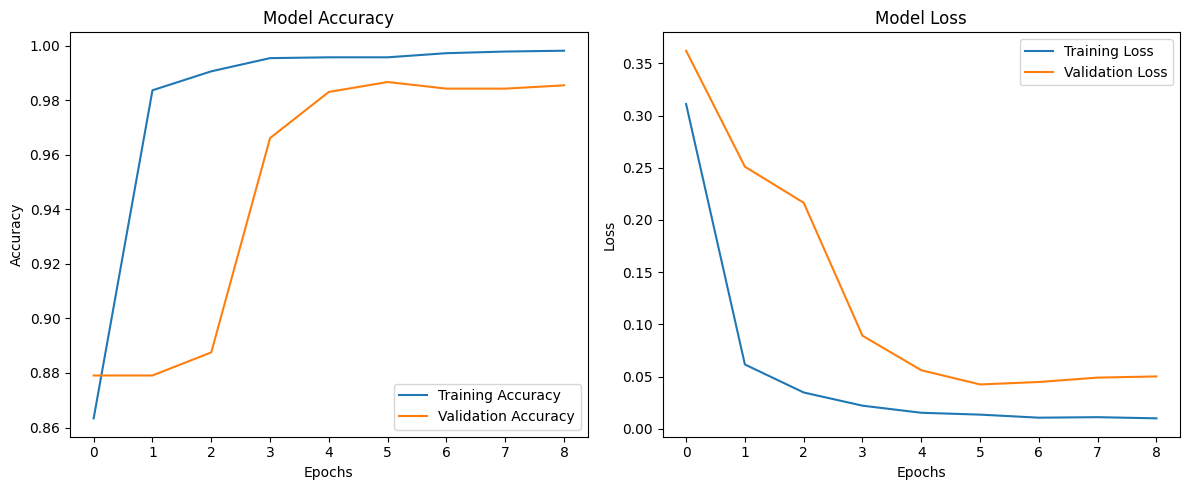

In [12]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Plot Training and Validation Loss

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
# Evaluate model on unseen test data

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Predict probabilities
y_prob = model.predict(X_test)

# Convert probabilities into class labels
y_pred = (y_prob > 0.5).astype(int).flatten()

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Test Accuracy:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

# ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Model Test Accuracy: 97.96905222437138 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.85      0.91       131

    accuracy                           0.98      1034
   macro avg       0.98      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034

ROC-AUC Score: 0.9914365177990245

Confusion Matrix:
[[901   2]
 [ 19 112]]


In [14]:
# Test the model with new SMS messages

sample_messages = [
    "Congratulations! You have won a free iPhone. Call now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! You have won a cash prize. Claim now!",
    "Hello friend, how are you doing today?"
]

# Convert messages using the trained TF-IDF vectorizer
sample_vectors = tfidf.transform(sample_messages).toarray()

# Predict probabilities
predictions = model.predict(sample_vectors)

# Display predictions with confidence
for message, prediction in zip(sample_messages, predictions):

    probability = float(prediction[0])

    if probability >= 0.5:
        result = "SPAM"
        confidence = probability * 100
    else:
        result = "HAM (NOT SPAM)"
        confidence = (1 - probability) * 100

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 60)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

Message: Congratulations! You have won a free iPhone. Call now!
Prediction: SPAM
Confidence: 75.69 %
------------------------------------------------------------

Message: Hey, are you coming to college tomorrow?
Prediction: HAM (NOT SPAM)
Confidence: 99.98 %
------------------------------------------------------------

Message: URGENT! You have won a cash prize. Claim now!
Prediction: SPAM
Confidence: 99.8 %
------------------------------------------------------------

Message: Hello friend, how are you doing today?
Prediction: HAM (NOT SPAM)
Confidence: 99.95 %
------------------------------------------------------------
